# Chapter 5 — Learning Multiple Weights at a Time: Generalizing Gradient Descent

> **Book:** *Grokking Deep Learning* (Andrew W. Trask, Manning)
> **Notebook goal:** summarize Chapter 5, explain every theory, and reproduce the code.

---

## 1. Chapter Summary

Chapter 4 learned **one** weight. Chapter 5 shows how the *same* idea scales to networks with many weights.

| Topic | Idea |
|---|---|
| Gradient descent, one weight (full derivation) | `delta = pred − goal`, `weight_delta = delta × input`, `weight −= alpha × weight_delta` |
| **Learning rate `alpha`** | scales each update. Too big → the error *diverges*; too small → very slow |
| **Divergence** | with a large input the update overshoots the minimum and the error explodes. `alpha` fixes that |
| Multiple inputs | one `delta`, one `weight_delta` **per weight** (`delta × input_i`) |
| **Freezing one weight** | if one weight is frozen, the others still learn and the error still goes to 0 — the network is flexible: *any* combination that yields the right prediction works |
| Multiple outputs | each output has its own `delta`; weight_delta = `input × delta_j` |
| Multiple inputs **and** outputs | weight_delta matrix = **outer product** of input vector and delta vector |
| **Visualizing weights** | weights can be shown as images (e.g. MNIST pixel weights) — they reveal what the network "looks for" |

---

## 2. Theory Deep-Dive

### 2.1 Gradient descent derived
Error for one weight: $E=(x w-y)^2$. Let $\delta=\hat y-y$ (the "pure error"):

$$\frac{\partial E}{\partial w}=2\delta x \;\;\Longrightarrow\;\; w \leftarrow w-\alpha\,\delta\,x$$

(The constant 2 is folded into $\alpha$.) The derivative has two parts:
* $\delta$ — how much and in what direction we missed;
* $x$ — *scaling / negative reversal / stopping*:
  * **Scaling**: bigger input → bigger weight update (bigger influence on the miss).
  * **Negative reversal**: for negative inputs the update sign flips (the weight must move the other way to affect the prediction in the desired direction).
  * **Stopping**: a zero input produces zero update — a weight that didn't participate can't be blamed.

### 2.2 Learning rate α and divergence
If the input is large, a tiny change in the weight causes a *huge* change in the prediction, so a full-size step overshoots the bottom and lands on the other (higher) side of the bowl; the next step overshoots even more → **divergence** (error grows). The cure is a small `alpha` (typically 10⁻¹…10⁻⁵ found by experiment):

$$w \leftarrow w-\alpha\,\delta\,x$$

### 2.3 Multiple inputs
Prediction $\hat y=\sum_i x_iw_i$. The single error $\delta$ is shared by all weights, but each weight gets its **own** gradient:
$$\Delta w_i=\delta\,x_i$$
Because every weight uses the same $\delta$, they all move to reduce the *same* error, each scaled by how large *its* input was.

### 2.4 Freezing a weight
If we do not update $w_0$ we still reach zero error — the other weights compensate. This shows the **error surface is a bowl in many dimensions with many weight combinations along the valley floor** and that learning is a *joint* optimisation.

### 2.5 Multiple outputs
Each output $j$ has its own error $\delta_j=\hat y_j-y_j$, and
$$\Delta w_{j}=\delta_j\,x$$
so every output weight is learned independently.

### 2.6 Multiple inputs and outputs
$$\Delta W=\boldsymbol\delta\,\mathbf x^{T}\quad(\text{outer product}),\qquad W\leftarrow W-\alpha\,\Delta W$$
The weight between input $i$ and output $j$ moves by $\delta_j x_i$.

### 2.7 What do weights mean?
Visualizing the learned weight vector of an output as an image (e.g. 28×28 pixels) shows *which inputs excite or inhibit* that output — a first glimpse at "what the network has learned".

---

## 3. Code Reproduction

### 3.1 Gradient descent with one weight + learning rate

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("folder-picture", exist_ok=True)

def train_one(weight, input_, goal, alpha, iters=20, verbose=False):
    errs = []
    for i in range(iters):
        pred = input_ * weight
        error = (pred - goal) ** 2
        delta = pred - goal
        weight_delta = delta * input_
        weight = weight - alpha * weight_delta
        errs.append(error)
        if verbose:
            print(f"Error:{error:.6f} Prediction:{pred:.6f}")
    return errs

print("Without alpha (alpha=1) but with a LARGE input (2) -> divergence:")
bad = train_one(0.5, 2, 0.8, alpha=1.0, iters=12, verbose=True)

Without alpha (alpha=1) but with a LARGE input (2) -> divergence:
Error:0.040000 Prediction:1.000000
Error:0.360000 Prediction:0.200000
Error:3.240000 Prediction:2.600000
Error:29.160000 Prediction:-4.600000
Error:262.440000 Prediction:17.000000
Error:2361.960000 Prediction:-47.800000
Error:21257.640000 Prediction:146.600000
Error:191318.760000 Prediction:-436.600000
Error:1721868.840000 Prediction:1313.000000
Error:15496819.560000 Prediction:-3935.800000
Error:139471376.040000 Prediction:11810.600000
Error:1255242384.360000 Prediction:-35428.600000


### 3.2 Fixing divergence with `alpha`

With alpha = 0.1:
final error: 1.485277170987127e-10


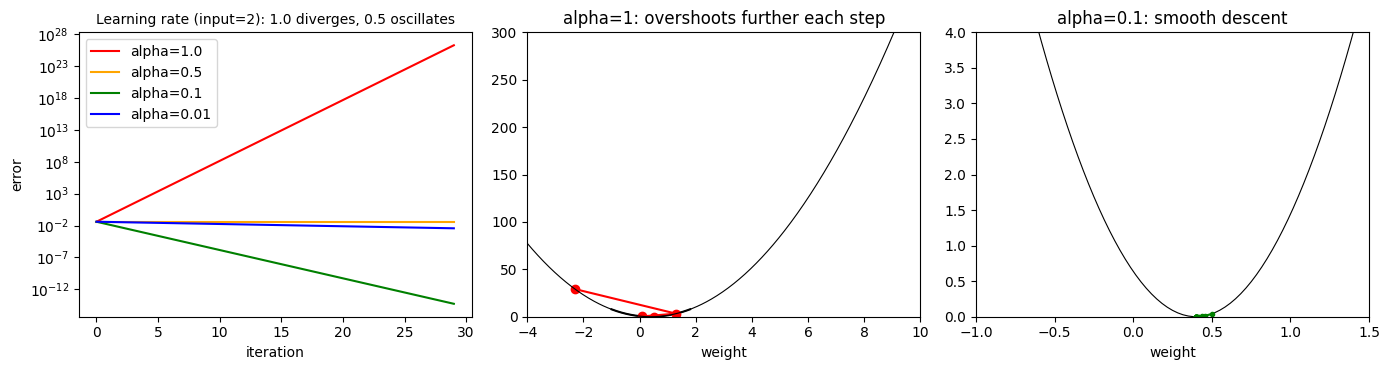

In [2]:
print("With alpha = 0.1:")
good = train_one(0.5, 2, 0.8, alpha=0.1, iters=20, verbose=False)
print("final error:", good[-1])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, c in zip([1.0, 0.5, 0.1, 0.01], ["r", "orange", "g", "b"]):
    e = train_one(0.5, 2, 0.8, a, iters=30)
    ax[0].plot(e, c=c, label=f"alpha={a}")
ax[0].set_yscale("log"); ax[0].set_title("Learning rate (input=2): 1.0 diverges, 0.5 oscillates", fontsize=10)
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("error"); ax[0].legend()

# error surface + overshoot path with alpha=1
ws = np.linspace(-1.0, 1.8, 200); E = (2 * ws - 0.8) ** 2
ax[1].plot(ws, E, "k")
w = 0.5; path = [w]
for _ in range(3):
    w -= 1.0 * (2 * w - 0.8) * 2; path.append(w)
ax[1].plot(path, [(2 * p - 0.8) ** 2 for p in path], "ro-")
ax[1].set_ylim(0, 300); ax[1].set_xlim(-4, 10)
ax[1].set_title("alpha=1: overshoots further each step")
xs = np.linspace(-10, 10, 600); ax[1].plot(xs, (2 * xs - 0.8) ** 2, "k", lw=0.8)
ax[1].set_xlabel("weight")

w = 0.5; path = [w]
for _ in range(20):
    w -= 0.1 * (2 * w - 0.8) * 2; path.append(w)
ax[2].plot(xs, (2 * xs - 0.8) ** 2, "k", lw=0.8)
ax[2].plot(path, [(2 * p - 0.8) ** 2 for p in path], "go-", ms=3)
ax[2].set_xlim(-1, 1.5); ax[2].set_ylim(0, 4); ax[2].set_xlabel("weight")
ax[2].set_title("alpha=0.1: smooth descent")
plt.tight_layout()
plt.savefig("folder-picture/ch05_learning_rate_divergence.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.3 Gradient descent with multiple inputs

In [3]:
def neural_network(input_, weights):
    return np.dot(input_, weights)

def ele_mul(number, vector):
    return number * np.asarray(vector)

toes   = np.array([8.5, 9.5, 9.9, 9.0])
wlrec  = np.array([0.65, 0.8, 0.8, 0.9])
nfans  = np.array([1.2, 1.3, 0.5, 1.0])
win_or_lose_binary = [1, 1, 0, 1]
true = win_or_lose_binary[0]

weights = np.array([0.1, 0.2, -0.1])
input_ = np.array([toes[0], wlrec[0], nfans[0]])
alpha = 0.01

w_hist = []
for iteration in range(3):
    pred = neural_network(input_, weights)
    error = (pred - true) ** 2
    delta = pred - true
    weight_deltas = ele_mul(delta, input_)
    print(f"Iteration:{iteration+1}  Pred:{pred:.4f}  Error:{error:.4f}")
    print("  Delta:", round(delta, 4), " Weight_Deltas:", np.round(weight_deltas, 4))
    weights = weights - alpha * weight_deltas
    print("  Weights:", np.round(weights, 4))

Iteration:1  Pred:0.8600  Error:0.0196
  Delta: -0.14  Weight_Deltas: [-1.19  -0.091 -0.168]
  Weights: [ 0.1119  0.2009 -0.0983]
Iteration:2  Pred:0.9638  Error:0.0013
  Delta: -0.0362  Weight_Deltas: [-0.3081 -0.0236 -0.0435]
  Weights: [ 0.115   0.2011 -0.0979]
Iteration:3  Pred:0.9906  Error:0.0001
  Delta: -0.0094  Weight_Deltas: [-0.0797 -0.0061 -0.0113]
  Weights: [ 0.1158  0.2012 -0.0978]


### 3.4 Training to convergence, and **freezing** one weight

final error  (all weights learn)   : 0.0
final error  (first weight frozen) : 1e-08
weights (all)    : [ 0.116  0.201 -0.098]
weights (frozen) : [ 0.1    0.249 -0.01 ]


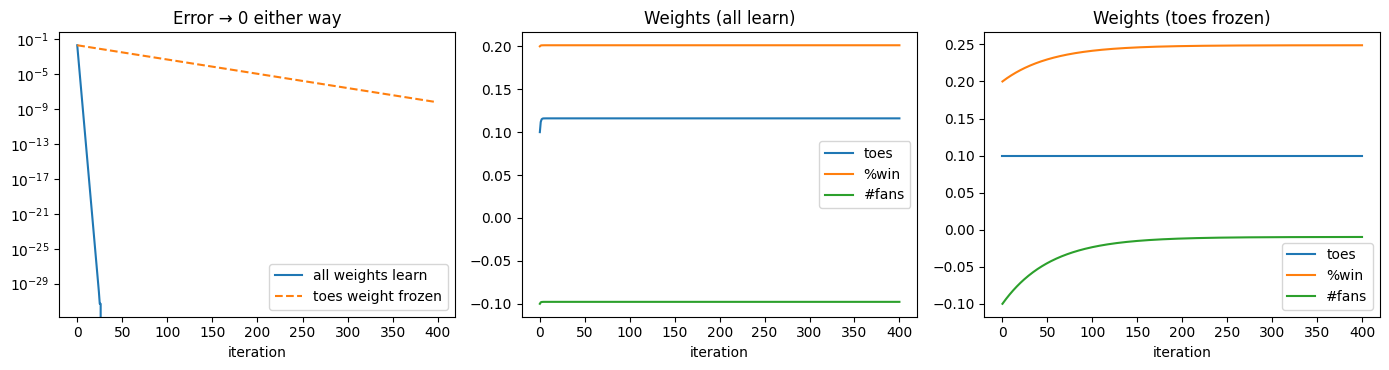

In [4]:
def train_multi(freeze_first=False, iters=400, alpha=0.01):
    w = np.array([0.1, 0.2, -0.1])
    errs, ws = [], [w.copy()]
    for _ in range(iters):
        pred = neural_network(input_, w)
        delta = pred - true
        errs.append(delta ** 2)
        wd = ele_mul(delta, input_)
        if freeze_first:
            wd[0] = 0                      # freeze the 'toes' weight
        w = w - alpha * wd
        ws.append(w.copy())
    return np.array(errs), np.array(ws)

e_all, w_all = train_multi(False)
e_frz, w_frz = train_multi(True)
print("final error  (all weights learn)   :", round(e_all[-1], 8))
print("final error  (first weight frozen) :", round(e_frz[-1], 8))
print("weights (all)    :", np.round(w_all[-1], 3))
print("weights (frozen) :", np.round(w_frz[-1], 3))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(e_all, label="all weights learn"); ax[0].plot(e_frz, label="toes weight frozen", ls="--")
ax[0].set_yscale("log"); ax[0].legend(); ax[0].set_title("Error → 0 either way"); ax[0].set_xlabel("iteration")
for k, n in enumerate(["toes", "%win", "#fans"]):
    ax[1].plot(w_all[:, k], label=n)
ax[1].set_title("Weights (all learn)"); ax[1].legend(); ax[1].set_xlabel("iteration")
for k, n in enumerate(["toes", "%win", "#fans"]):
    ax[2].plot(w_frz[:, k], label=n)
ax[2].set_title("Weights (toes frozen)"); ax[2].legend(); ax[2].set_xlabel("iteration")
plt.tight_layout()
plt.savefig("folder-picture/ch05_multiple_inputs_freezing.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.5 Gradient descent with multiple outputs

In [5]:
weights = np.array([0.3, 0.2, 0.9])

def neural_network(input_, weights):
    return input_ * weights

wlrec_ = [0.65, 1.0, 1.0, 0.9]
hurt   = [0.1, 0.0, 0.0, 0.1]
win    = [1, 1, 0, 1]
sad    = [0.1, 0.0, 0.1, 0.2]

input_ = wlrec_[0]
true = np.array([hurt[0], win[0], sad[0]])
alpha = 0.1

for it in range(50):
    pred = neural_network(input_, weights)
    error = (pred - true) ** 2
    delta = pred - true
    weight_deltas = input_ * delta
    weights = weights - alpha * weight_deltas
print("final predictions [hurt, win, sad]:", np.round(pred, 3))
print("targets                           :", true)

final predictions [hurt, win, sad]: [0.111 0.895 0.158]
targets                           : [0.1 1.  0.1]


### 3.6 Gradient descent with multiple inputs **and** outputs (outer product)

In [6]:
weights = np.array([[0.1, 0.1, -0.3],
                    [0.1, 0.2,  0.0],
                    [0.0, 1.3,  0.1]])

def neural_network(input_, weights):
    return input_.dot(weights.T)

toes2  = np.array([8.5, 9.5, 9.9, 9.0])
input_ = np.array([toes2[0], wlrec_[0], nfans[0]])
true   = np.array([hurt[0], win[0], sad[0]])
alpha  = 0.01

err_hist = []
for it in range(200):
    pred = neural_network(input_, weights)
    delta = pred - true
    err_hist.append((delta ** 2).sum())
    weight_deltas = np.outer(delta, input_)      # shape (outputs, inputs)
    weights = weights - alpha * weight_deltas

print("final predictions:", np.round(pred, 3), " targets:", true)

final predictions: [0.1 1.  0.1]  targets: [0.1 1.  0.1]


### 3.7 What do weights "look like"? (visualising a weight matrix)

We use a tiny 5×5 "image" input to see how an output unit's weights, after training, reflect the pattern it was taught to detect.

pred(plus)= 1.0 pred(diag)= 0.0


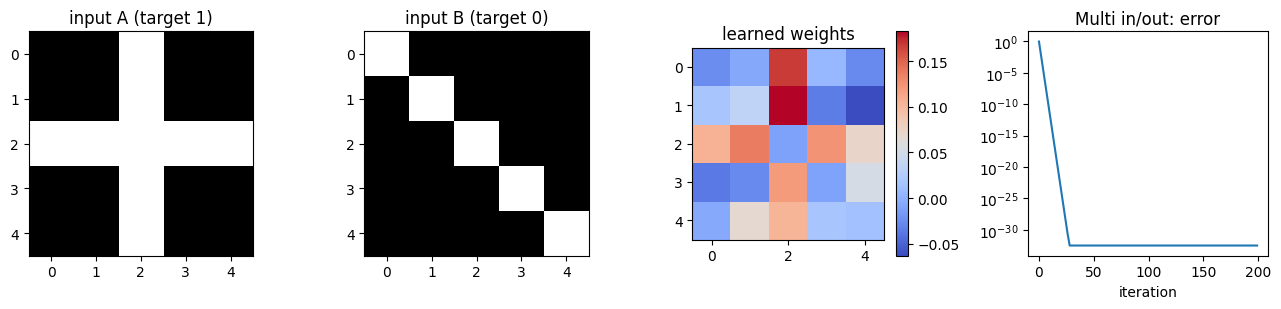

In [7]:
rng = np.random.default_rng(0)
# two patterns on 5x5 grid: a plus sign (class 1) and a diagonal (class 0)
plus = np.zeros((5, 5)); plus[2, :] = 1; plus[:, 2] = 1
diag = np.eye(5)
X = np.stack([plus.ravel(), diag.ravel()])
Y = np.array([1.0, 0.0])

w = rng.normal(0, 0.05, 25)
for _ in range(300):
    for x, y in zip(X, Y):
        delta = x @ w - y
        w -= 0.05 * delta * x
print("pred(plus)=", round(X[0] @ w, 3), "pred(diag)=", round(X[1] @ w, 3))

fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
ax[0].imshow(plus, cmap="gray"); ax[0].set_title("input A (target 1)")
ax[1].imshow(diag, cmap="gray"); ax[1].set_title("input B (target 0)")
im = ax[2].imshow(w.reshape(5, 5), cmap="coolwarm"); ax[2].set_title("learned weights"); plt.colorbar(im, ax=ax[2])
ax[3].plot(err_hist); ax[3].set_yscale("log"); ax[3].set_title("Multi in/out: error"); ax[3].set_xlabel("iteration")
plt.tight_layout()
plt.savefig("folder-picture/ch05_weights_visualisation.png", dpi=120, bbox_inches="tight")
plt.show()

Positive (red) weights sit where the plus sign has pixels that the diagonal does **not**; negative (blue) weights appear on the diagonal-only pixels. The weights literally encode *"what to look for"*.

---

## 4. Key Takeaways

* The full update rule is **`weight -= alpha * delta * input`** — one `delta` per output, one gradient per weight.
* **`alpha`** prevents divergence by shrinking each step.
* With many weights, each gets its own gradient but they share the same error signal; some weights can be frozen and the rest compensate.
* For several inputs and outputs the weight update is an **outer product** of `delta` and `input`.
* Weights can be viewed as images to understand what a network detects.

➡️ **Next:** Chapter 6 — building a *deep* network (hidden layers, non-linearity, **backpropagation**).